In [ ]:
#from google.colab import drive
#drive.mount("/content/drive")

from pathlib import Path
import os
#PROJECT_ROOT=Path("/content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments")
#if not PROJECT_ROOT.exists(): raise FileNotFoundError(PROJECT_ROOT)
#os.chdir(PROJECT_ROOT)
#print("Project root:",Path.cwd())


Mounted at /content/drive
Project root: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments


In [ ]:
!python -m src.train_group_dro

Device: cpu
config.json: 100% 483/483 [00:00<00:00, 1.87MB/s]
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 167kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 9.96MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 22.4MB/s]

model.safetensors: downloading bytes:  67% 179M/268M [00:01<00:00, 226MB/s, 14.6MB/s  ]
model.safetensors: downloading bytes:  82% 220M/268M [00:01<00:00, 215MB/s, 19.4MB/s  ]
model.safetensors: downloading bytes:  93% 250M/268M [00:01<00:00, 190MB/s, 22.4MB/s  ]
model.safetensors: downloading bytes: 100% 250M/250M [00:02<00:00, 118MB/s, 23.2MB/s  ]
model.safetensors: reconstructing file: 100% 268M/268M [00:02<00:00, 126MB/s, 25.1MB/s  ]
Loading weights: 100% 100/100 [00:00<00:00, 4749.52it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.we

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

ERM_PATH = Path("results/erm/test_predictions.csv")
DRO_PATH = Path("results/group_dro/test_predictions.csv")

for p in [ERM_PATH, DRO_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Missing prediction file: {p}")

IDENTITY_COLUMNS = [
    "male", "female", "LGBTQ", "christian",
    "muslim", "other_religions", "black", "white"
]


In [ ]:
erm = pd.read_csv(ERM_PATH)
dro = pd.read_csv(DRO_PATH)

required = {"true_label", "prediction"} | set(IDENTITY_COLUMNS)
for name, df in [("ERM", erm), ("Group DRO", dro)]:
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {sorted(missing)}")

if "uid" in erm.columns and "uid" in dro.columns:
    assert erm["uid"].is_unique and dro["uid"].is_unique
    dro_small = dro[["uid", "true_label", "prediction"]].rename(columns={"prediction":"dro_prediction","true_label":"dro_true_label"})
    combined = erm.merge(dro_small, on="uid", how="inner", validate="one_to_one")
    assert len(combined) == len(erm)
    assert np.array_equal(combined["true_label"].values, combined["dro_true_label"].values)
    combined = combined.drop(columns=["dro_true_label"]).rename(columns={"prediction":"erm_prediction"})
else:
    assert len(erm) == len(dro)
    assert np.array_equal(erm["true_label"].values, dro["true_label"].values)
    combined = erm.copy().rename(columns={"prediction":"erm_prediction"})
    combined["dro_prediction"] = dro["prediction"].values

print("Test examples:", len(combined))


Test examples: 132730



### Change only SELECTED_IDENTITY here


In [ ]:
SELECTED_IDENTITY = "christian"

if SELECTED_IDENTITY not in IDENTITY_COLUMNS:
    raise ValueError(
        f"Choose one of: {IDENTITY_COLUMNS}"
    )

print("Selected identity:", SELECTED_IDENTITY)


Selected identity: christian


In [ ]:
identity_subset = combined[combined[SELECTED_IDENTITY] >= 0.5].copy()

if len(identity_subset) == 0:
    raise ValueError(f"No positive examples found for {SELECTED_IDENTITY}")

print("Identity-positive examples:", len(identity_subset))
print("Label distribution:")
print(identity_subset["true_label"].value_counts().sort_index())


Identity-positive examples: 13304
Label distribution:
true_label
0    12050
1     1254
Name: count, dtype: int64


In [ ]:
rows=[]
for label_value, label_name in [(0,"non-toxic"),(1,"toxic")]:
    group=identity_subset[identity_subset["true_label"]==label_value]
    if len(group)==0:
        continue
    rows.append({
        "identity":SELECTED_IDENTITY,
        "label":label_value,
        "label_name":label_name,
        "n":len(group),
        "ERM_accuracy":accuracy_score(group["true_label"],group["erm_prediction"]),
        "GroupDRO_accuracy":accuracy_score(group["true_label"],group["dro_prediction"]),
    })

label_results=pd.DataFrame(rows)
label_results["accuracy_change"] = label_results["GroupDRO_accuracy"] - label_results["ERM_accuracy"]
label_results.round(4)


,identity,label,label_name,n,ERM_accuracy,GroupDRO_accuracy,accuracy_change
0,christian,0,non-toxic,12050,0.9731,0.9150,-0.0581
1,christian,1,toxic,1254,0.4809,0.6938,0.2129


## Overall accuracy


In [ ]:
overall = pd.DataFrame({
    "Method":["ERM","Group DRO"],
    "Accuracy":[
        accuracy_score(identity_subset["true_label"],identity_subset["erm_prediction"]),
        accuracy_score(identity_subset["true_label"],identity_subset["dro_prediction"]),
    ]
})
overall.round(4)


,Method,Accuracy
0,ERM,0.9267
1,Group DRO,0.8942


## False-positive and false-negative rates


In [ ]:
non_toxic = identity_subset[identity_subset["true_label"] == 0]
toxic = identity_subset[identity_subset["true_label"] == 1]

error_rates = pd.DataFrame({
    "Method":["ERM","Group DRO"],
    "False_positive_rate":[
        np.nan if len(non_toxic)==0 else (non_toxic["erm_prediction"]==1).mean(),
        np.nan if len(non_toxic)==0 else (non_toxic["dro_prediction"]==1).mean(),
    ],
    "False_negative_rate":[
        np.nan if len(toxic)==0 else (toxic["erm_prediction"]==0).mean(),
        np.nan if len(toxic)==0 else (toxic["dro_prediction"]==0).mean(),
    ],
})
error_rates.round(4)


,Method,False_positive_rate,False_negative_rate
0,ERM,0.0269,0.5191
1,Group DRO,0.0850,0.3062


## Plot

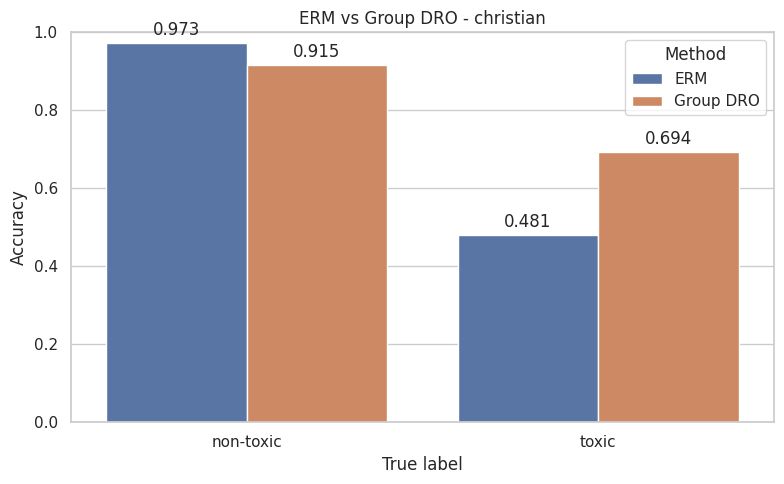

In [ ]:
plot_df=label_results.melt(
    id_vars=["identity","label_name","n"],
    value_vars=["ERM_accuracy","GroupDRO_accuracy"],
    var_name="Method", value_name="Accuracy"
)
plot_df["Method"] = plot_df["Method"].replace({"ERM_accuracy":"ERM","GroupDRO_accuracy":"Group DRO"})

plt.figure(figsize=(8,5))
ax=sns.barplot(data=plot_df,x="label_name",y="Accuracy",hue="Method")
for container in ax.containers:
    ax.bar_label(container,fmt="%.3f",padding=3)
plt.ylim(0,1)
plt.xlabel("True label")
plt.ylabel("Accuracy")
plt.title(f"ERM vs Group DRO - {SELECTED_IDENTITY}")
plt.tight_layout()
plt.show()


In [ ]:
all_rows=[]
for identity in IDENTITY_COLUMNS:
    positive=combined[combined[identity]>=0.5]
    for label_value,label_name in [(0,"non-toxic"),(1,"toxic")]:
        group=positive[positive["true_label"]==label_value]
        if len(group)==0:
            continue
        erm_acc=accuracy_score(group["true_label"],group["erm_prediction"])
        dro_acc=accuracy_score(group["true_label"],group["dro_prediction"])
        all_rows.append({"identity":identity,"label":label_value,"label_name":label_name,"n":len(group),"ERM_accuracy":erm_acc,"GroupDRO_accuracy":dro_acc,"change":dro_acc-erm_acc})

all_groups=pd.DataFrame(all_rows)
display(all_groups.sort_values("ERM_accuracy").round(4))


,identity,label,label_name,n,ERM_accuracy,GroupDRO_accuracy,change
7,christian,1,toxic,1254,0.4809,0.6938,0.2129
5,LGBTQ,1,toxic,1205,0.5137,0.7734,0.2598
9,muslim,1,toxic,1616,0.5149,0.7277,0.2129
3,female,1,toxic,2252,0.5466,0.7469,0.2003
11,other_religions,1,toxic,517,0.5513,0.7408,0.1896
1,male,1,toxic,2187,0.5665,0.7398,0.1733
15,white,1,toxic,2208,0.6209,0.7794,0.1585
13,black,1,toxic,1517,0.6341,0.8082,0.1740
12,black,0,non-toxic,3317,0.8565,0.6515,-0.2050
14,white,0,non-toxic,5644,0.8676,0.6951,-0.1726


## Worst groups for each method


In [ ]:
erm_worst=all_groups.sort_values("ERM_accuracy").iloc[0]
dro_worst=all_groups.sort_values("GroupDRO_accuracy").iloc[0]
print("ERM worst evaluated group:")
print(erm_worst)
print("Group DRO worst evaluated group:")
print(dro_worst)


ERM worst evaluated group:
identity             christian
label                        1
label_name               toxic
n                         1254
ERM_accuracy          0.480861
GroupDRO_accuracy      0.69378
change                0.212919
Name: 7, dtype: object
Group DRO worst evaluated group:
identity                 black
label                        0
label_name           non-toxic
n                         3317
ERM_accuracy          0.856497
GroupDRO_accuracy     0.651492
change               -0.205005
Name: 12, dtype: object
